# Questão 8 — O formato da loss sob desbalanceamento de classes

## A pergunta

> *Qual loss da mais resultado na classe minoritária a FLOPs iguais, e ela muda a geometria da
> representação oculta como Müller et al. afirmam?*

76 % das linhas do Adult são `<=50K`. A entropia cruzada trata todas as linhas igualmente, e o
modelo pode marcar 0,76 ignorando a classe minoritária. Uma família de losses tenta corrigir
isso sem custo de FLOPs: a **focal** reduz o peso dos exemplos fáceis, o **label smoothing**
suaviza os alvos e a **PolyLoss** repondera o primeiro termo da expansão da entropia cruzada.
Este notebook mede se alguma delas funciona, usando só o engine do repositório (`bert_cpu`).

## O que a literatura prevê para este cenário, e as hipóteses

Os quatro artigos trabalham a três ordens de grandeza daqui (ImageNet, COCO, redes profundas
em GPU). O que cada um prevê quando trazido para um MLP raso em 108 features tabulares, com
24 % de positivos:

| Artigo | O que afirma | O que prevê aqui |
|---|---|---|
| Lin et al. (focal) | reduzir o peso dos exemplos fáceis resolve o desbalanceamento extremo (~1:1000) da detecção densa | com 1:3 e poucos exemplos "triviais", o ganho deve ser pequeno; sem o termo $\alpha$, a focal não desloca a fronteira para a minoria |
| Szegedy et al. (label smoothing) | suavizar os alvos regulariza e evita logits enormes | pouco a regularizar em 100 passos de um modelo com 7 mil parâmetros |
| Müller et al. | o smoothing aperta os clusters da penúltima camada em volta dos templates e melhora a calibração | clusters mais apertados e silhueta maior; calibração melhor *só se* a CE estiver superconfiante |
| Leng et al. (Poly-1) | ajustar o peso do termo $(1-p_t)$ rende alguns décimos de ponto em vários benchmarks | um efeito, se houver, da ordem de décimos de ponto, perto do ruído entre seeds |

Hipóteses, na forma em que podem ser refutadas:

- **H1.** Nenhuma das três losses "de formato" melhora a acurácia balanceada no teste em mais
  de um desvio-padrão entre seeds em relação à CE.
- **H2.** O que a CE ponderada ganha no recall de `>50K` é um deslocamento do limiar: a CE com
  o limiar ajustado na validação alcança a mesma acurácia balanceada (±1 dp) sem FLOPs extras.
- **H3.** O label smoothing aumenta a silhueta da penúltima camada (o `silhouette_score` do
  `benchmark.py`) e aperta os clusters no plano dos templates, mais quanto maior o
  $\varepsilon$, como afirmam Müller et al.
- **H4.** Esse aperto não se traduz em melhor ordenação: o ROC-AUC do label smoothing não
  supera o da CE.

In [38]:
import gc
import json
import pathlib
import sys
import time

ROOT = pathlib.Path.cwd()
while not (ROOT / "bert_cpu").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import datasets
from bert_cpu import engine as cpu
from bert_cpu.engine import Tensor
from research.benchmark import (MLP, Result, baseline_mlp, load_adult_cached, pareto,
                                run_adult, silhouette_score, summarize, train_val_split)

HERE = ROOT / "experiments" / "loss_imbalance"
RESULTS = HERE / "results"
FIGURES = HERE / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# Paleta e estilo das figuras (as mesmas cores em todas, prontas para slide).
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.style.use("default")             # fundo claro, independente do tema do Jupyter
plt.rcParams.update({
    "font.size": 11, "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})

T_START = time.time()
print("pronto — engine importado de", ROOT)

pronto — engine importado de C:\Users\pedro\PycharmProjects\BERT-cpu


## 1. O problema e o que fica fixo

Cada seed sorteia uma divisão 80/20 de `adult.data` em treino e validação e fixa a
inicialização dos pesos. O `adult.test` (16 281 linhas) só é olhado nos runs finais.

O que torna a comparação **a FLOPs iguais** é fixar todo o resto: o mesmo MLP da q05, o mesmo
Adam full-batch com lr 1e-2 e os mesmos 100 passos. A loss só acrescenta algumas operações
elemento a elemento no topo do grafo, e o contador do engine vai mostrar quanto isso custa.

Antes de treinar, vale fixar a referência burra: sempre responder `<=50K` acerta 76 %, e não
encontra nenhum `>50K`. Por isso a acurácia sozinha esconde o efeito que queremos medir.

In [39]:
train_ds, test_ds = load_adult_cached()
print(train_ds, test_ds)
for name, ds in (("treino", train_ds), ("teste", test_ds)):
    print(f"{name:7s}: {ds.y.size:6,d} linhas   fração >50K = {ds.y.mean():.3f}")
print(f"\n'sempre <=50K' no teste: acurácia {1 - test_ds.y.mean():.3f}")

AdultDataset(split='train', n_features=108, n_samples=32561) AdultDataset(split='test', n_features=108, n_samples=16281)
treino : 32,561 linhas   fração >50K = 0.241
teste  : 16,281 linhas   fração >50K = 0.236

'sempre <=50K' no teste: acurácia 0.764


### O baseline, reproduzido antes de mudar qualquer coisa

O protocolo do projeto pede que o ponto de partida seja reproduzido antes de qualquer
variação. `research/benchmark.py` garante que `run_adult(baseline_mlp, seed=0)` dá a acurácia
de teste da q05, **0,8543**, com **84 227 782 200** FLOPs de treino. A célula seguinte confere isso.

In [40]:
t0 = time.time()
base = run_adult(baseline_mlp, seed=0, name="baseline (q05)")
print(f"acurácia de teste = {base.score:.4f}   (q05: 0.8543)")
print(f"FLOPs de treino   = {base.train_flops:,}   (q05: 84,227,782,200)")
print(f"tempo             = {time.time() - t0:.1f} s")
assert round(base.score, 4) == 0.8543 and base.train_flops == 84_227_782_200
del base
gc.collect()

acurácia de teste = 0.8543   (q05: 0.8543)
FLOPs de treino   = 84,227,782,200   (q05: 84,227,782,200)
tempo             = 10.1 s


24732

## 2. As cinco losses

**Notação.** O modelo produz os logits $z$ e as probabilidades $p = \mathrm{softmax}(z)$. Para cada exemplo, $p_t$ é a probabilidade dada à **classe correta** ($t$ de *target*). No Adult, $K = 2$ classes: `<=50K` (majoritária, 75,9%) e `>50K` (minoritária, 24,1%).

| Loss | Fórmula por exemplo | Hiperparâmetro | O que muda em relação à CE |
|---|---|---|---|
| CE | $-\log p_t$ | — | (referência) |
| CE ponderada | $w_t\,(-\log p_t)$ | — | pesa cada exemplo pela **classe** |
| Focal (Lin et al.) | $-(1-p_t)^{\gamma}\log p_t$ | $\gamma$ | pesa cada exemplo pela **dificuldade** |
| Label smoothing (Szegedy et al.) | $-\sum_c q_c \log p_c$ | $\varepsilon$ | troca o **alvo** por um alvo suavizado |
| Poly-1 (Leng et al.) | $-\log p_t + \varepsilon_1 (1-p_t)$ | $\varepsilon_1$ | soma um termo **linear** à CE |

### 2.1 Cross entropy (CE)

$$\mathcal{L}_{\text{CE}} = -\log p_t$$

É a referência. A loss é zero só quando $p_t = 1$ e cresce rápido quando o modelo erra. Todas as classes contam igual, então, com 76% dos exemplos na classe majoritária, o gradiente é dominado por ela.

Exemplo: $p_t = 0{,}8 \Rightarrow 0{,}223$; $\;p_t = 0{,}2 \Rightarrow 1{,}609$.

### 2.2 CE ponderada por classe

$$\mathcal{L}_{\text{W}} = \frac{\sum_i w_{t_i}\,(-\log p_{t_i})}{\sum_i w_{t_i}}, \qquad w_c = \frac{N}{K\,N_c} = \frac{1}{K\,f_c}, \quad f_c = \frac{N_c}{N}$$

em que $N$ é o total de exemplos de treino, $N_c$ é o número de exemplos da classe $c$ e $f_c$ é a fração dessa classe.

- $1/f_c$ é o **inverso da frequência**: quanto mais rara a classe, maior o peso.
- $1/K$ só ajusta a escala: cada classe soma o mesmo peso total ($N_c\,w_c = N/K$) e o peso médio por exemplo fica em 1.
- Dividir por $\sum w$ faz uma média ponderada no lote, mantendo a loss na escala da CE (o learning rate não muda).
- Com classes balanceadas, todo $w_c = 1$ e a fórmula vira a CE.

| Classe | $N_c$ | $f_c$ | $w_c$ |
|---|---|---|---|
| `>50K` (minoritária) | 7 841 | 0,241 | **2,08** |
| `<=50K` (majoritária) | 24 720 | 0,759 | **0,66** |

Um erro na classe minoritária pesa cerca de **3,2×** mais. Na prática, isso equivale a deslocar o limiar de decisão a favor da classe rara.

### 2.3 Focal loss

$$\mathcal{L}_{\text{FL}} = -(1-p_t)^{\gamma}\,\log p_t$$

O fator $(1-p_t)^{\gamma}$ diminui o peso dos exemplos **fáceis** (com $p_t$ perto de 1) e mantém o dos difíceis. Com $\gamma = 0$ ela é a CE; quanto maior o $\gamma$, mais forte o efeito. A ideia do artigo é que, com desbalanceamento, a maioria dos exemplos fáceis vem da classe majoritária, e a focal impede que eles dominem o treino.

Exemplo com $\gamma = 2$: $p_t = 0{,}8 \Rightarrow 0{,}2^2 \cdot 0{,}223 = 0{,}009$; $\;p_t = 0{,}2 \Rightarrow 0{,}8^2 \cdot 1{,}609 = 1{,}030$. Na CE o erro feio pesa 7× o fácil; na focal, 116×.

Usamos a versão sem o peso $\alpha$ por classe do artigo. Com $\alpha$, ela passaria a misturar o efeito da CE ponderada, que já está na comparação, e não daria para separar o efeito do formato da loss.

### 2.4 Label smoothing

$$\mathcal{L}_{\text{LS}} = -\sum_{c=1}^{K} q_c \log p_c, \qquad q = (1-\varepsilon)\,\mathbf{1}_t + \frac{\varepsilon}{K}$$

É a CE com o **alvo trocado**: em vez de 1 na classe correta e 0 na outra, o alvo vira $1 - \varepsilon + \varepsilon/K$ e $\varepsilon/K$. Com $\varepsilon = 0{,}1$ e $K = 2$: $q = (0{,}95;\ 0{,}05)$. A loss passa a ser mínima em $p_t = 0{,}95$ e **pune** o modelo se ele ficar mais confiante que isso, o que segura o crescimento dos logits. Segundo Müller et al., isso também aperta os clusters de cada classe na camada oculta.

Exemplo com $\varepsilon = 0{,}1$: $p_t = 0{,}8 \Rightarrow -(0{,}95 \log 0{,}8 + 0{,}05 \log 0{,}2) = 0{,}292$. O mínimo possível é 0,199, em $p_t = 0{,}95$, e não 0.

### 2.5 Poly-1

$$\mathcal{L}_{\text{Poly-1}} = -\log p_t + \varepsilon_1\,(1-p_t)$$

A CE pode ser escrita como a série $\sum_{j \ge 1} (1-p_t)^j / j$. O Poly-1 muda só o peso do **primeiro termo**, de 1 para $1 + \varepsilon_1$. Com $\varepsilon_1 > 0$, o modelo continua sendo empurrado com força mesmo nos exemplos que já acerta; com $\varepsilon_1 < 0$, o contrário. Com $\varepsilon_1 = 0$ é a CE.

Exemplo com $\varepsilon_1 = 1$: $p_t = 0{,}8 \Rightarrow 0{,}223 + 0{,}2 = 0{,}423$; $\;p_t = 0{,}2 \Rightarrow 1{,}609 + 0{,}8 = 2{,}409$.

### Implementação

Todas usam o `softmax` do engine e são montadas só com operações do `Tensor`, então o `backward()` chega aos pesos sem código novo. Cada uma tem a assinatura `loss_fn(model, X, y) -> Tensor escalar`, que é o que `research.benchmark.run_adult` espera.

In [41]:
def probabilities(model, X):
    """Probabilidade de cada classe para cada pessoa: tabela (N pessoas, K classes)."""
    return model(X).T.softmax(axis=-1)


def onehot_targets(y, p):
    """Rótulos viram linhas 0/1, no mesmo formato de p. Ex.: y = [0, 1] -> [[1, 0], [0, 1]]."""
    targets = np.zeros(p.shape, dtype=p.data.dtype)
    targets[np.arange(len(y)), y] = 1.0
    return targets


def true_class_prob(p, targets):
    """p_t: zera as classes erradas e soma o que sobrou em cada linha."""
    return (p * targets).sum(axis=-1)


def ce_loss():
    def loss_fn(model, X, y):
        p = probabilities(model, X)
        p_t = true_class_prob(p, onehot_targets(y, p))
        return -p_t.log().mean()
    return loss_fn


def weighted_ce_loss():
    """Pesos inversos à frequência, calculados nos rótulos do treino (o batch é o treino todo)."""
    def loss_fn(model, X, y):
        p = probabilities(model, X)
        p_t = true_class_prob(p, onehot_targets(y, p))
        w = len(y) / (p.shape[-1] * np.bincount(y)[y])     # w_c = N / (K N_c), um por pessoa
        return -(p_t.log() * w).sum() / w.sum()
    return loss_fn


def focal_loss(gamma):
    def loss_fn(model, X, y):
        p = probabilities(model, X)
        p_t = true_class_prob(p, onehot_targets(y, p))
        modulator = (1.0 + 1e-12 - p_t) ** gamma           # 1e-12: evita 0 ** (gamma-1) no backward
        return -(modulator * p_t.log()).mean()
    return loss_fn


def label_smoothing_loss(eps):
    def loss_fn(model, X, y):
        p = probabilities(model, X)
        K = p.shape[-1]
        smooth_targets = onehot_targets(y, p) * (1 - eps) + eps / K
        return -(p.log() * smooth_targets).sum(axis=-1).mean()
    return loss_fn


def poly1_loss(eps1):
    def loss_fn(model, X, y):
        p = probabilities(model, X)
        p_t = true_class_prob(p, onehot_targets(y, p))
        return (-p_t.log() + (1.0 - p_t) * eps1).mean()
    return loss_fn

LOSSES = {"ce": ce_loss, "wce": weighted_ce_loss, "focal": focal_loss,
          "ls": label_smoothing_loss, "poly1": poly1_loss}


def build_loss(family, param=None):
    """Ex.: build_loss("ce") -> ce_loss(); build_loss("focal", 0.5) -> focal_loss(0.5)."""
    return LOSSES[family]() if param is None else LOSSES[family](param)

NAMES = {"ce": "CE", "wce": "Weighted CE", "focal": "Focal γ", "ls": "Label smoothing ε", "poly1": "Poly-1 ε₁"}


def label(family, param=None):
    """Ex.: label("ce") -> "CE"; label("focal", 0.5) -> "Focal γ=0.5"."""
    return NAMES[family] if param is None else f"{NAMES[family]}={param:g}"

### Conferindo as losses

Três checagens num modelo minúsculo:

1. Com o hiperparâmetro em zero, focal, label smoothing e Poly-1 **viram a CE**; a diferença
   para o `cross_entropy` da biblioteca tem de ser ~1e-16.
2. O gradiente que o engine produz para os pesos da última camada tem de bater com
   **diferenças finitas centrais** (o mesmo critério dos exercícios q01–q04: ~1e-9 ou menos).
3. Cálculo manual esperado dos valores das losses

In [42]:
from research.benchmark import default_loss


def loss_gradient_check(loss_fn, model, X, y, h=1e-6):
    """Maior diferença entre o gradiente do backward e o de diferenças finitas, nos pesos de fc2."""
    for q in model.parameters():
        q.zero_grad()
    loss_fn(model, X, y).backward()

    W = model.fc2.weight
    analytic = W.grad.copy()
    numeric = np.zeros_like(analytic)
    for i in range(W.data.size):
        old = W.data.flat[i]
        W.data.flat[i] = old + h
        up = float(loss_fn(model, X, y).data)
        W.data.flat[i] = old - h
        down = float(loss_fn(model, X, y).data)
        W.data.flat[i] = old                              # devolve o peso original
        numeric.flat[i] = (up - down) / (2 * h)           # derivada central
    return np.abs(analytic - numeric).max()


def check_losses() -> None:
    """(1) Com hiperparâmetro 0, focal, LS e Poly-1 viram a CE do benchmark.
    (2) O backward de cada loss bate com diferenças finitas."""
    cpu.set_seed(0)
    model = MLP(5, hidden=8)
    X = cpu.Tensor(np.random.randn(5, 40), requires_grad=False)
    y = (np.random.rand(40) < 0.3).astype(int)            # ~30% de classe 1, desbalanceado
    all_ok = True

    print("1. Casos que devem ser iguais à CE do benchmark (default_loss):\n")
    ref = float(default_loss(model, X, y).data)
    for family, param in [("ce", None), ("focal", 0.0), ("ls", 0.0), ("poly1", 0.0)]:
        diff = abs(float(build_loss(family, param)(model, X, y).data) - ref)
        ok = diff < 1e-10
        all_ok = all_ok and ok
        print(f"  {label(family, param):22s} |diferença| = {diff:.1e}  -> {'PASS' if ok else 'FAIL'}")

    print("\n2. Gradiente (backward analítico vs diferenças finitas):\n")
    for family, param in [("wce", None), ("focal", 0.5), ("focal", 2.0), ("ls", 0.2), ("poly1", 2.0)]:
        worst = loss_gradient_check(build_loss(family, param), model, X, y)
        ok = worst < 1e-6
        all_ok = all_ok and ok
        print(f"  {label(family, param):22s} max|analítico - numérico| = {worst:.1e}  -> {'PASS' if ok else 'FAIL'}")

    print("\nTodas as losses passaram." if all_ok else "\nAlguma loss falhou: veja os FAIL acima.")


check_losses()

1. Casos que devem ser iguais à CE do benchmark (default_loss):

  CE                     |diferença| = 1.1e-16  -> PASS
  Focal γ=0              |diferença| = 1.1e-16  -> PASS
  Label smoothing ε=0    |diferença| = 1.1e-16  -> PASS
  Poly-1 ε₁=0            |diferença| = 1.1e-16  -> PASS

2. Gradiente (backward analítico vs diferenças finitas):

  Weighted CE            max|analítico - numérico| = 7.2e-11  -> PASS
  Focal γ=0.5            max|analítico - numérico| = 5.4e-11  -> PASS
  Focal γ=2              max|analítico - numérico| = 2.9e-11  -> PASS
  Label smoothing ε=0.2  max|analítico - numérico| = 4.3e-11  -> PASS
  Poly-1 ε₁=2            max|analítico - numérico| = 2.4e-10  -> PASS

Todas as losses passaram.


In [43]:
class FixedModel:
    """Finge ser um modelo: sempre dá p = (0.2, 0.8) para todas as pessoas."""
    def __init__(self, n):
        self.logits = np.array([[0.0] * n, [np.log(4.0)] * n])   # softmax(0, ln 4) = (0.2, 0.8)
    def __call__(self, X):
        return cpu.Tensor(self.logits, requires_grad=False)


def check_hand_values() -> None:
    """Compara cada loss com o valor calculado à mão."""
    one = FixedModel(1)
    y1 = np.array([1])                       # uma pessoa >50K, então p_t = 0.8
    four = FixedModel(4)
    y4 = np.array([1, 0, 0, 0])              # 1 rara (p_t = 0.8) e 3 comuns (p_t = 0.2)

    cases = [
        ("ce",    None, one,  y1, 0.22314),  # -log(0.8)
        ("focal", 2.0,  one,  y1, 0.00893),  # 0.2² · 0.22314
        ("ls",    0.1,  one,  y1, 0.29246),  # 0.95·0.22314 + 0.05·1.60944
        ("poly1", 1.0,  one,  y1, 0.42314),  # 0.22314 + 1·0.2
        ("ce",    None, four, y4, 1.26287),  # (0.22314 + 3·1.60944) / 4
        ("wce",   None, four, y4, 0.91629),  # pesos 2 e 0.667: (2·0.22314 + 3·0.667·1.60944) / 4
    ]
    all_ok = True
    for family, param, model, y, expected in cases:
        got = float(build_loss(family, param)(model, None, y).data)
        ok = abs(got - expected) < 1e-4
        all_ok = all_ok and ok
        print(f"  {label(family, param):22s} esperado {expected:.5f}  obtido {got:.5f}  -> {'PASS' if ok else 'FAIL'}")
    print("\nTodas batem com a conta à mão." if all_ok else "\nAlguma fórmula está errada: veja os FAIL acima.")


check_hand_values()

  CE                     esperado 0.22314  obtido 0.22314  -> PASS
  Focal γ=2              esperado 0.00893  obtido 0.00893  -> PASS
  Label smoothing ε=0.1  esperado 0.29246  obtido 0.29246  -> PASS
  Poly-1 ε₁=1            esperado 0.42314  obtido 0.42314  -> PASS
  CE                     esperado 1.26287  obtido 1.26286  -> PASS
  Weighted CE            esperado 0.91629  obtido 0.91629  -> PASS

Todas batem com a conta à mão.


## 3. O que medir na classe minoritária

A classe 1 (`>50K`) é a minoritária em tudo o que segue.

- **Precisão e recall de `>50K`**, e o F1 entre eles.
- **Acurácia balanceada** $= \tfrac12(\text{recall}_{>50K} + \text{recall}_{\le 50K})$: o
  "sempre `<=50K`" marca 0,5 aqui, não 0,76.
- **ROC-AUC e PR-AUC**, que não dependem do limiar de decisão. Elas separam duas coisas que
  uma loss pode fazer: *ordenar melhor* os exemplos (a AUC sobe) ou só *deslocar o limiar*
  (a AUC fica igual e a precisão troca por recall).
- **Calibração.** O ECE (Guo et al. 2017) agrupa as previsões em 15 faixas de confiança e
  mede a distância média entre confiança e acerto; o diagrama de confiabilidade desenha isso.
  Abaixo da diagonal o modelo está superconfiante, acima está subconfiante.

Há também um **controle de custo zero**: o próprio modelo CE, com o limiar em
$p(>50K)$ escolhido na validação para maximizar a acurácia balanceada. Se uma loss só desloca
o limiar, esse controle chega ao mesmo lugar sem gastar nada.

In [44]:
def classification(p1, y, threshold=0.5):
    pred = (p1 >= threshold).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    prec, rec, spec = tp / max(tp + fp, 1), tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    return {"acc": (tp + tn) / len(y), "min_precision": prec, "min_recall": rec,
            "min_f1": 2 * prec * rec / max(prec + rec, 1e-12), "maj_recall": spec,
            "bal_acc": 0.5 * (rec + spec), "pos_rate": float(pred.mean())}


def roc_auc(p1, y):
    """Mann-Whitney U, com postos médios nos empates."""
    order = np.argsort(p1, kind="mergesort"); sp = p1[order]
    ranks = np.empty(len(p1)); i = 0
    while i < len(p1):
        j = i
        while j + 1 < len(p1) and sp[j + 1] == sp[i]:
            j += 1
        ranks[order[i:j + 1]] = 0.5 * (i + j) + 1.0
        i = j + 1
    n_pos = int((y == 1).sum()); n_neg = len(y) - n_pos
    return float((ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def average_precision(p1, y):
    yy = y[np.argsort(-p1, kind="mergesort")]
    return float((np.cumsum(yy) / np.arange(1, len(yy) + 1) * yy).sum() / max(yy.sum(), 1))


def reliability(p1, y, n_bins=15):
    """Curva de confiabilidade top-label e ECE."""
    conf = np.maximum(p1, 1.0 - p1)
    correct = ((p1 >= 0.5).astype(int) == y).astype(float)
    edges = np.linspace(0.5, 1.0, n_bins + 1)
    idx = np.clip(np.digitize(conf, edges[1:-1], right=True), 0, n_bins - 1)
    bconf, bacc, bn = np.full(n_bins, np.nan), np.full(n_bins, np.nan), np.zeros(n_bins, int)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        bn[b] = int(m.sum())
        if bn[b]:
            bconf[b], bacc[b] = conf[m].mean(), correct[m].mean()
            ece += bn[b] / len(y) * abs(bacc[b] - bconf[b])
    return float(ece), bconf, bacc, bn


def all_metrics(p1, y, threshold=0.5):
    out = classification(p1, y, threshold)
    p_t = np.where(y == 1, p1, 1.0 - p1)
    out.update(ece=reliability(p1, y)[0], roc_auc=roc_auc(p1, y), pr_auc=average_precision(p1, y),
               nll=float(-np.log(np.clip(p_t, 1e-12, 1.0)).mean()))
    return out


def best_threshold(p1, y):
    """Limiar em p(>50K) que maximiza a acurácia balanceada (escolhido na validação)."""
    grid = np.linspace(0.02, 0.98, 97)
    return float(grid[int(np.argmax([classification(p1, y, t)["bal_acc"] for t in grid]))])

## 4. A hipótese de Müller et al.

Müller, Kornblith & Hinton projetam as ativações da penúltima camada no plano gerado pelos
**templates** das classes, isto é, as colunas $w_k$ da última camada (o logit da classe $k$ é
$h \cdot w_k$). A afirmação deles: com label smoothing, cada classe vira um **cluster
apertado** em volta do seu template, enquanto com CE as ativações se espalham.

Aqui $h = \mathrm{ReLU}(\text{fc1}(x)) \in \mathbb{R}^{64}$, e os templates são as colunas de
`fc2.weight` sem a linha do bias. Com duas classes o plano tem um eixo especial: a decisão só
depende de $h \cdot (w_1 - w_0)$. Por isso o eixo horizontal das figuras é $w_1 - w_0$ e o
vertical é o resto do plano.

Tudo é medido nas mesmas 2 000 linhas do teste, sorteadas uma vez.

Uma limitação na metade da afirmação de Müller, que os
clusters ficam **equidistantes dos templates das outras classes**, só é testável com $K \ge 3$.
Com $K = 2$ ela é trivial.


### Medidas de geometria

Notação: $h_i \in \mathbb{R}^{64}$ é a ativação da pessoa $i$, $y_i$ a classe dela, $n_c$ o número de pessoas da classe $c$, $\mu_c$ a média das ativações da classe $c$ e $\mu$ a média geral.

**Plano dos templates** (`template_plane`). O eixo horizontal é a direção da decisão, e o vertical é a soma dos templates, ortogonalizada:

$$a = \frac{w_1 - w_0}{\lVert w_1 - w_0 \rVert}, \qquad \tilde b = (w_0 + w_1) - \big((w_0 + w_1)\cdot a\big)\,a, \qquad b = \frac{\tilde b}{\lVert \tilde b \rVert}$$

$$p_i = (h_i \cdot a,\; h_i \cdot b)$$

**NC1**: variância dentro das classes sobre a variância entre as classes, em 64-d. Menor significa mais apertado.

$$\mathrm{NC1} = \frac{\sum_c \sum_{i \in c} \lVert h_i - \mu_c \rVert^2}{\sum_c n_c \,\lVert \mu_c - \mu \rVert^2}$$

**Spread**: raio médio de cada classe no plano, relativo à distância entre os centros $m_c$ (média dos $p_i$ da classe). Menor significa mais apertado.

$$\mathrm{spread}_c = \frac{\sqrt{\frac{1}{n_c}\sum_{i \in c} \lVert p_i - m_c \rVert^2}}{\lVert m_1 - m_0 \rVert}$$

**d′**: separação no eixo da decisão, com $d_i = h_i \cdot a$. Maior significa mais separado.

$$d' = \frac{\lvert \bar d_1 - \bar d_0 \rvert}{\sqrt{\tfrac12(\sigma_0^2 + \sigma_1^2)}}$$

**Silhueta**: para cada pessoa, $\alpha_i$ é a distância média até a própria classe e $\beta_i$ até a outra. Varia de −1 a 1, e maior significa mais separado.

$$s_i = \frac{\beta_i - \alpha_i}{\max(\alpha_i, \beta_i)}, \qquad S = \frac{1}{n}\sum_i s_i$$

| Versão | Distância | Espaço |
|---|---|---|
| `sil_cosine` | $1 - \cos(h_i, h_j)$ | $h$, 64-d |
| `sil_full` | euclidiana | $h$, 64-d |
| `sil_plane` | euclidiana | $p$, 2-d |

As medidas são relativas, ou invariantes à escala, porque o label smoothing também encolhe as ativações: um espalhamento absoluto menor poderia ser só efeito de tudo ter ficado menor.

In [45]:
def template_plane(H, W):
    # H: ativações da camada escondida, (n pessoas, 64)
    # W: pesos da camada de saída sem a linha do bias, (64, 2)
    #    coluna 0 = template w0 (≤50K), coluna 1 = template w1 (>50K)

    # Eixo horizontal: a direção w1 - w0, com tamanho 1.
    # Andar nessa direção aumenta z1 - z0, ou seja, puxa a decisão para >50K.
    a = W[:, 1] - W[:, 0]
    a = a / np.linalg.norm(a)

    # Eixo vertical: parte de w0 + w1 e tira o pedaço que aponta na direção de a
    # (Gram-Schmidt), para os dois eixos ficarem perpendiculares.
    b = W[:, 0] + W[:, 1]
    b = b - (b @ a) * a
    # 1e-12 evita dividir por zero se w0 + w1 for paralelo a a (por exemplo, w0 = -w1)
    b = b / max(np.linalg.norm(b), 1e-12)

    # Projeção: o produto escalar com cada eixo dá a coordenada da pessoa nele.
    # Resultado: (n, 2), coluna 0 = x, coluna 1 = y
    return np.stack([H @ a, H @ b], axis=1)


def silhouette_euclid(Z, labels):
    sq = (Z ** 2).sum(1)
    D = np.sqrt(np.maximum(sq[:, None] + sq[None, :] - 2 * Z @ Z.T, 0.0))
    s = np.zeros(len(Z))
    for i in range(len(Z)):
        same = labels == labels[i]; same[i] = False
        a, b = D[i, same].mean(), D[i, labels != labels[i]].mean()
        s[i] = (b - a) / max(a, b, 1e-12)
    return float(s.mean())


def geometry(H, y, W):
    mu = H.mean(0); Sw = Sb = 0.0
    for c in (0, 1):
        Hc = H[y == c]; mc = Hc.mean(0)
        Sw += ((Hc - mc) ** 2).sum(); Sb += len(Hc) * ((mc - mu) ** 2).sum()
    P = template_plane(H, W)
    gap = np.linalg.norm(P[y == 1].mean(0) - P[y == 0].mean(0))
    spread = {c: np.sqrt(((P[y == c] - P[y == c].mean(0)) ** 2).sum(1).mean()) / gap for c in (0, 1)}
    d = P[:, 0]
    pooled = np.sqrt(0.5 * (d[y == 0].var() + d[y == 1].var()))
    return {"nc1": float(Sw / Sb), "spread_maj": float(spread[0]), "spread_min": float(spread[1]),
            "dprime": float(abs(d[y == 1].mean() - d[y == 0].mean()) / pooled),
            "sil_cosine": silhouette_score(H, y),       # a do benchmark.py (cosseno, 64-d)
            "sil_plane": silhouette_euclid(P, y), "sil_full": silhouette_euclid(H, y)}

O ponto zero honesto da silhueta (como o `silhouette_before` da q06) é a silhueta das
**próprias features de entrada**, nas mesmas 2 000 linhas: o quanto as classes já estavam
separadas antes de qualquer camada aprendida.

In [46]:
GEO_IDX = np.random.default_rng(12345).choice(test_ds.y.size, 2000, replace=False)
sil_input = silhouette_score(test_ds.X[:, GEO_IDX].T, test_ds.y[GEO_IDX])
print(f"silhouette_score das 108 features de entrada (2 000 linhas do teste) = {sil_input:+.3f}")

silhouette_score das 108 features de entrada (2 000 linhas do teste) = +0.074


## 5. Utilitário: treinar e medir

`run_adult` (de `research/benchmark.py`) é o laço da q05 com a loss como parâmetro, e devolve
o modelo treinado junto com os FLOPs de treino. A função abaixo treina uma configuração numa
seed e mede tudo das seções 3 e 4.

In [47]:
def forward_parts(model, X):
    """Forward sem gradiente: devolve p(>50K) de cada pessoa e as ativações da camada oculta (n, 64)."""
    h = model.fc1(cpu.Tensor(X, requires_grad=False)).relu()
    logits = model.fc2(h).data
    z = np.exp(logits - logits.max(0, keepdims=True))          # softmax
    return (z / z.sum(0, keepdims=True))[1], h.data.T


def validation_predictions(model, seed):
    """Refaz a mesma divisão treino/validação do run_adult e prevê a validação."""
    cpu.set_seed(seed)
    _, _, X_val, y_val = train_val_split(train_ds.X, train_ds.y)
    p_val, _ = forward_parts(model, X_val)
    return p_val, y_val


def final_evaluation(model, p_val, y_val, family, param, seed):
    """Só para os modelos finais: teste, limiar, calibração e geometria."""
    p_te, H = forward_parts(model, test_ds.X)
    y_te = test_ds.y
    thr = best_threshold(p_val, y_val)                         # limiar escolhido na validação
    _, bconf, bacc, bn = reliability(p_te, y_te)
    W = model.fc2.weight.data[1:]                              # sem a linha do bias
    if seed == 0:                                              # guardado para as figuras
        np.savez_compressed(RESULTS / f"proj_{family}_{param}.npz",
                            P=template_plane(H[GEO_IDX], W), y=y_te[GEO_IDX],
                            p=p_te[GEO_IDX], p_full=p_te)
    return {
        "test": all_metrics(p_te, y_te),
        "val_threshold": thr,
        "test_at_val_threshold": all_metrics(p_te, y_te, thr),
        "reliability": {"conf": bconf.tolist(), "acc": bacc.tolist(), "n": bn.tolist()},
        "geometry": geometry(H[GEO_IDX], y_te[GEO_IDX], W),
    }


def run_one(family, param, seed, final=False):
    """Treina uma loss com uma seed e devolve uma linha com todas as métricas."""

    #PART 1 - Treinamento
    t0 = time.time()
    res = run_adult(
        baseline_mlp,
        seed=seed,
        loss_fn=build_loss(family, param),
        name=label(family, param)
    )

    # PART 2 - Validação
    model = res.extra["model"]

    p_val, y_val = validation_predictions(model, seed)
    row = {
        "family": family,
        "param": param,
        "seed": seed,
        "name": label(family, param),
        "train_flops": res.train_flops,
        "infer_flops": res.infer_flops,
        "n_params": res.extra["n_params"],
        "val": all_metrics(p_val, y_val)}
    if final:
        row.update(final_evaluation(model, p_val, y_val, family, param, seed))

    row["seconds"] = time.time() - t0
    del res, model
    gc.collect()
    return row

## 6. Etapa 1: sweep dos hiperparâmetros (só validação)

Cada loss com hiperparâmetro tem seu valor escolhido na **validação**, nunca no teste:

- focal: $\gamma \in \{0{,}5;\ 1;\ 2;\ 3;\ 5\}$
- label smoothing: $\varepsilon \in \{0{,}05;\ 0{,}1;\ 0{,}2;\ 0{,}3\}$
- Poly-1: $\varepsilon_1 \in \{-1;\ 1;\ 2;\ 5\}$

Três seeds por valor. O critério é a **acurácia
balanceada média na validação**, porque a pergunta é sobre a classe minoritária e a
acurácia simples pode enviesar.

`USE_CACHE = True` lê `results/sweep.json` e `results/final.json` se existirem, em vez de
treinar de novo. Deixe `False` para refazer tudo do zero (12 a 20 min no total).

In [48]:
USE_CACHE = False

SWEEP = ([("ce", None)]
         + [("focal", g) for g in (0.5, 1.0, 2.0, 3.0, 5.0)]
         + [("ls", e) for e in (0.05, 0.1, 0.2, 0.3)]
         + [("poly1", e) for e in (-1.0, 1.0, 2.0, 5.0)]
         + [("wce", None)])
SWEEP_SEEDS = (0, 1, 2)

if USE_CACHE and (RESULTS / "sweep.json").exists():
    sweep = json.loads((RESULTS / "sweep.json").read_text())
    print(f"sweep lido de results/ ({len(sweep)} runs)")
else:
    sweep, t0 = [], time.time()
    for k, (fam, p) in enumerate(SWEEP):
        for s in SWEEP_SEEDS:
            sweep.append(run_one(fam, p, s))
        print(f"[{k + 1:2d}/{len(SWEEP)}] {label(fam, p):24s} {time.time() - t0:5.0f} s")
    (RESULTS / "sweep.json").write_text(json.dumps(sweep, indent=1))

[ 1/15] CE                          16 s
[ 2/15] Focal γ=0.5                 30 s
[ 3/15] Focal γ=1                   43 s
[ 4/15] Focal γ=2                   57 s
[ 5/15] Focal γ=3                   70 s
[ 6/15] Focal γ=5                   84 s
[ 7/15] Label smoothing ε=0.05      98 s
[ 8/15] Label smoothing ε=0.1      111 s
[ 9/15] Label smoothing ε=0.2      125 s
[10/15] Label smoothing ε=0.3      138 s
[11/15] Poly-1 ε₁=-1               152 s
[12/15] Poly-1 ε₁=1                166 s
[13/15] Poly-1 ε₁=2                179 s
[14/15] Poly-1 ε₁=5                193 s
[15/15] Weighted CE                206 s


In [49]:
def mean_sd(xs):
    xs = np.asarray(xs, dtype=float)
    return xs.mean(), xs.std(ddof=1)


def sweep_table(rows):
    lines = ["| Loss | Acur. balanceada | Recall >50K | Precisão >50K | ECE | ROC-AUC |",
             "|---|---|---|---|---|---|"]
    for name in dict.fromkeys(r["name"] for r in rows):
        rs = [r for r in rows if r["name"] == name]
        cell = lambda k: "%.4f ± %.4f" % mean_sd([r["val"][k] for r in rs])
        lines.append(f"| {name} | {cell('bal_acc')} | {cell('min_recall')} | "
                     f"{cell('min_precision')} | {cell('ece')} | {cell('roc_auc')} |")
    return "\n".join(lines)


selected = {}
for fam in ("focal", "ls", "poly1"):
    params = sorted({r["param"] for r in sweep if r["family"] == fam})
    score = {p: np.mean([r["val"]["bal_acc"] for r in sweep
                         if r["family"] == fam and r["param"] == p]) for p in params}
    selected[fam] = max(score, key=score.get)

display(Markdown("**Validação, seeds 0–2, limiar 0,5 (média ± dp)**\n\n" + sweep_table(sweep)))
print("selecionados:", {label(f, p) for f, p in selected.items()})

**Validação, seeds 0–2, limiar 0,5 (média ± dp)**

| Loss | Acur. balanceada | Recall >50K | Precisão >50K | ECE | ROC-AUC |
|---|---|---|---|---|---|
| CE | 0.7775 ± 0.0085 | 0.6339 ± 0.0212 | 0.7158 ± 0.0168 | 0.0162 ± 0.0029 | 0.9086 ± 0.0028 |
| Focal γ=0.5 | 0.7775 ± 0.0086 | 0.6335 ± 0.0221 | 0.7169 ± 0.0173 | 0.0252 ± 0.0045 | 0.9082 ± 0.0028 |
| Focal γ=1 | 0.7747 ± 0.0098 | 0.6286 ± 0.0232 | 0.7135 ± 0.0148 | 0.0560 ± 0.0026 | 0.9080 ± 0.0032 |
| Focal γ=2 | 0.7773 ± 0.0083 | 0.6329 ± 0.0207 | 0.7170 ± 0.0173 | 0.1101 ± 0.0047 | 0.9078 ± 0.0031 |
| Focal γ=3 | 0.7765 ± 0.0077 | 0.6300 ± 0.0178 | 0.7195 ± 0.0167 | 0.1515 ± 0.0045 | 0.9074 ± 0.0032 |
| Focal γ=5 | 0.7757 ± 0.0075 | 0.6288 ± 0.0160 | 0.7182 ± 0.0108 | 0.2059 ± 0.0060 | 0.9066 ± 0.0037 |
| Label smoothing ε=0.05 | 0.7767 ± 0.0069 | 0.6299 ± 0.0197 | 0.7208 ± 0.0192 | 0.0218 ± 0.0030 | 0.9080 ± 0.0025 |
| Label smoothing ε=0.1 | 0.7756 ± 0.0065 | 0.6265 ± 0.0187 | 0.7229 ± 0.0186 | 0.0342 ± 0.0035 | 0.9070 ± 0.0024 |
| Label smoothing ε=0.2 | 0.7754 ± 0.0071 | 0.6252 ± 0.0197 | 0.7248 ± 0.0182 | 0.0690 ± 0.0027 | 0.9063 ± 0.0027 |
| Label smoothing ε=0.3 | 0.7744 ± 0.0076 | 0.6229 ± 0.0189 | 0.7248 ± 0.0152 | 0.1036 ± 0.0042 | 0.9055 ± 0.0024 |
| Poly-1 ε₁=-1 | 0.7750 ± 0.0076 | 0.6292 ± 0.0192 | 0.7132 ± 0.0158 | 0.0689 ± 0.0050 | 0.9076 ± 0.0030 |
| Poly-1 ε₁=1 | 0.7766 ± 0.0073 | 0.6306 ± 0.0196 | 0.7190 ± 0.0167 | 0.0368 ± 0.0044 | 0.9092 ± 0.0025 |
| Poly-1 ε₁=2 | 0.7747 ± 0.0061 | 0.6264 ± 0.0170 | 0.7181 ± 0.0181 | 0.0527 ± 0.0027 | 0.9090 ± 0.0023 |
| Poly-1 ε₁=5 | 0.7746 ± 0.0069 | 0.6245 ± 0.0179 | 0.7221 ± 0.0154 | 0.0711 ± 0.0046 | 0.9081 ± 0.0021 |
| Weighted CE | 0.8229 ± 0.0052 | 0.8479 ± 0.0137 | 0.5682 ± 0.0120 | 0.0469 ± 0.0030 | 0.9059 ± 0.0042 |

selecionados: {'Poly-1 ε₁=1', 'Focal γ=0.5', 'Label smoothing ε=0.05'}


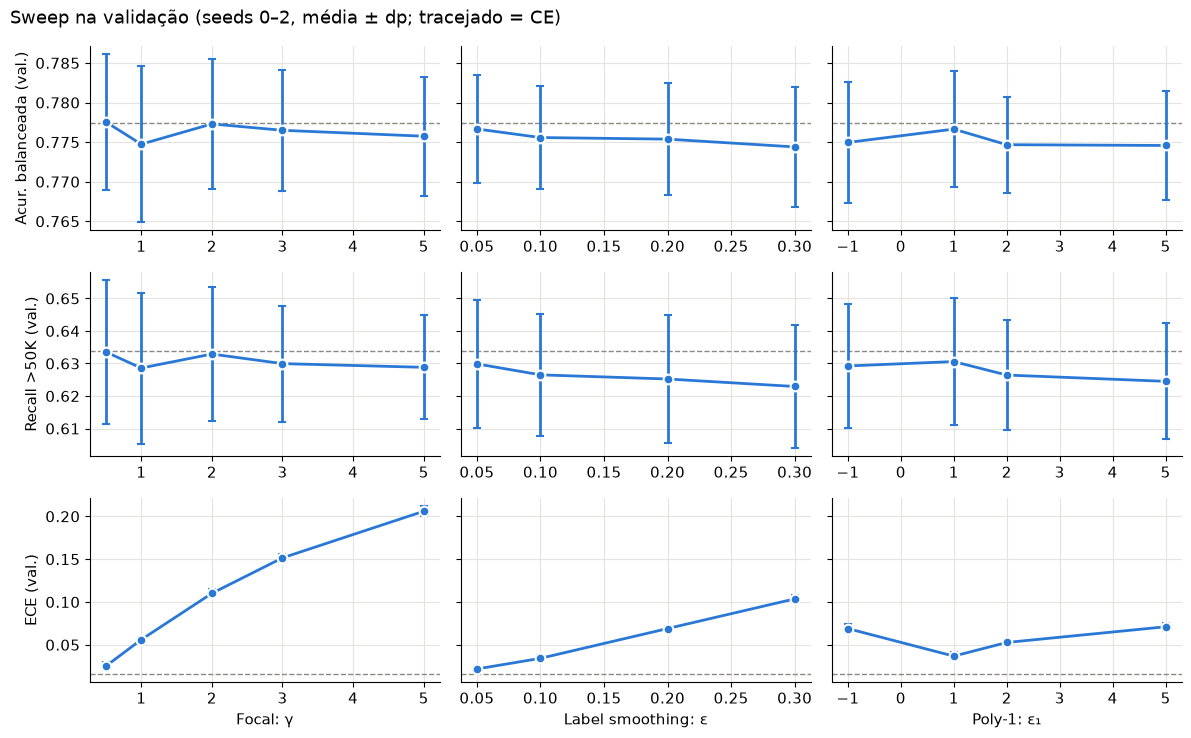

In [50]:
fams = [("focal", "Focal: γ"), ("ls", "Label smoothing: ε"), ("poly1", "Poly-1: ε₁")]
mets = [("bal_acc", "Acur. balanceada (val.)"), ("min_recall", "Recall >50K (val.)"), ("ece", "ECE (val.)")]
ce_rows = [r for r in sweep if r["family"] == "ce"]

fig, axes = plt.subplots(3, 3, figsize=(12, 7.5), sharey="row")
for j, (fam, xl) in enumerate(fams):
    ps = sorted({r["param"] for r in sweep if r["family"] == fam})
    for i, (k, yl) in enumerate(mets):
        ax = axes[i, j]
        ms = [mean_sd([r["val"][k] for r in sweep if r["family"] == fam and r["param"] == p]) for p in ps]
        ax.axhline(np.mean([r["val"][k] for r in ce_rows]), color=GRAY, ls="--", lw=1)
        ax.errorbar(ps, [m for m, _ in ms], yerr=[s for _, s in ms], color=BLUE, marker="o",
                    ms=7, capsize=3, markeredgecolor="white", markeredgewidth=1.5)
        if i == 2:
            ax.set_xlabel(xl)
        if j == 0:
            ax.set_ylabel(yl)
fig.suptitle("Sweep na validação (seeds 0–2, média ± dp; tracejado = CE)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig3_sweep_validation.png")
plt.show()

**O que o sweep mostra.** Nenhum $\gamma$, $\varepsilon$ ou $\varepsilon_1$ passa da CE na
acurácia balanceada. As diferenças entre valores (milésimos) são menores que o desvio entre
seeds (≈ 0,008), então a "escolha" do melhor valor é em boa parte ruído: o que sai daqui é
o valor menos agressivo de cada família. O ECE, ao contrário, piora com clareza conforme o
hiperparâmetro cresce.



## 7. Etapa 2: runs finais no teste

Dez seeds (0–9) por configuração, medidas no `adult.test`:

- CE e CE ponderada;
- focal, label smoothing e Poly-1 com o valor escolhido na etapa 1;
- label smoothing com $\varepsilon \in \{0{,}1;\ 0{,}2;\ 0{,}3\}$ e focal com $\gamma = 2$, de acordo com os autores.

In [ ]:
FINAL_SEEDS = tuple(range(10))
EXTRA_FINAL = [("ls", 0.1), ("ls", 0.2), ("ls", 0.3), ("focal", 2.0)]

configs = [("ce", None),
           ("wce", None),
           ("focal", selected["focal"]),
           ("ls", selected["ls"]),
           ("poly1", selected["poly1"])]

configs += [c for c in EXTRA_FINAL if c not in configs]

if USE_CACHE and (RESULTS / "final.json").exists():
    runs = json.loads((RESULTS / "final.json").read_text())["runs"]
    print(f"finais lidos de results/ ({len(runs)} runs)")
else:
    runs, t0 = [], time.time()
    for k, (fam, p) in enumerate(configs):
        for s in FINAL_SEEDS:
            runs.append(run_one(fam, p, s, final=True))
        print(f"[{k + 1:2d}/{len(configs)}] {label(fam, p):24s} {time.time() - t0:5.0f} s")
    (RESULTS / "final.json").write_text(json.dumps({"selected": selected, "runs": runs}, indent=1))

[ 1/9] CE                          55 s
[ 2/9] Weighted CE                106 s
[ 3/9] Focal γ=0.5                158 s
[ 4/9] Label smoothing ε=0.05     208 s
[ 5/9] Poly-1 ε₁=1                260 s
[ 6/9] Label smoothing ε=0.1      316 s


### O custo: FLOPs de treino por loss

O contador do engine soma tudo o que foi executado durante os 100 passos. Se a comparação é
mesmo a FLOPs iguais, as diferenças entre losses têm de ser desprezíveis.

In [ ]:
MAIN = ["CE", "Weighted CE", label("focal", selected["focal"]),
        label("ls", selected["ls"]), label("poly1", selected["poly1"])]
EXTRA = [n for n in dict.fromkeys(r["name"] for r in runs) if n not in MAIN]
THR = "CE + limiar da validação"


def vals(name, key, block="test"):
    """Os 10 valores de uma métrica, ordenados por seed (para o pareamento)."""
    if name == THR:
        rows, block = [r for r in runs if r["name"] == "CE"], "test_at_val_threshold"
    else:
        rows = [r for r in runs if r["name"] == name]
    return np.array([r[block][key] for r in sorted(rows, key=lambda r: r["seed"])])


ce_flops = [r for r in runs if r["name"] == "CE"][0]["train_flops"]
lines = ["| Loss | FLOPs de treino | vs CE |", "|---|---|---|"]
for n in MAIN + EXTRA:
    f = [r for r in runs if r["name"] == n][0]["train_flops"]
    lines.append(f"| {n} | {f:,} | {100 * (f / ce_flops - 1):+.3f} % |")
lines.append(f"| {THR} | {ce_flops:,} | +0.000 % (a busca do limiar é NumPy, fora do grafo) |")
display(Markdown("\n".join(lines)))

## 8. O que cada loss compra na classe minoritária

Primeiro a tabela completa, depois as diferenças **pareadas** contra a CE. Como a seed $s$ dá a
todas as losses a mesma divisão e a mesma inicialização, comparamos $\Delta_s =
\text{métrica}_s(\text{loss}) - \text{métrica}_s(\text{CE})$ e testamos
$t = \bar\Delta / (s_\Delta / \sqrt{10})$; $|t| > 2{,}26$ é $p < 0{,}05$ com 9 graus de
liberdade (sem correção para comparações múltiplas).

In [ ]:
def fmt(xs, nd=3):
    m, s = mean_sd(xs)
    return f"{m:.{nd}f} ± {s:.{nd}f}"


cols = [("acc", "Acurácia"), ("min_precision", "Precisão >50K"), ("min_recall", "Recall >50K"),
        ("min_f1", "F1 >50K"), ("bal_acc", "Acur. balanceada"), ("roc_auc", "ROC-AUC"),
        ("pr_auc", "PR-AUC"), ("ece", "ECE")]
arms = MAIN + [THR] + EXTRA
lines = ["| Loss | " + " | ".join(h for _, h in cols) + " |", "|---|" + "---|" * len(cols)]
for n in arms:
    lines.append(f"| {n} | " + " | ".join(fmt(vals(n, k)) for k, _ in cols) + " |")
display(Markdown("**Teste, limiar 0,5, 10 seeds (média ± dp)**\n\n" + "\n".join(lines)))

keys = [("min_recall", "Recall >50K"), ("min_precision", "Precisão >50K"),
        ("bal_acc", "Acur. balanceada"), ("roc_auc", "ROC-AUC"), ("ece", "ECE")]
lines = ["| Loss | " + " | ".join(h for _, h in keys) + " |", "|---|" + "---|" * len(keys)]
for n in arms[1:]:
    cells = []
    for k, _ in keys:
        d = vals(n, k) - vals("CE", k)
        m, s = mean_sd(d)
        if s == 0:
            cells.append("idêntico")
            continue
        t = m / (s / np.sqrt(len(d)))
        cells.append(f"{m:+.4f} (t={t:+.1f}){' *' if abs(t) > 2.26 else ''}")
    lines.append(f"| {n} | " + " | ".join(cells) + " |")
display(Markdown("**Δ pareado contra a CE** (`*` = |t| > 2,26)\n\n" + "\n".join(lines)))

### A tabela e a figura do protocolo: `summarize()` e `pareto()`

O relatório do projeto pede a tabela de `summarize()` com o baseline nela e a figura de
`pareto()`, para que esta questão possa ser lida ao lado das outras catorze. Os runs viram
objetos `Result` do `benchmark.py`. Como a pergunta é sobre a classe minoritária, o `score`
é a **acurácia balanceada**; a segunda tabela repete com a acurácia simples. `summarize`
marca se cada diferença para o baseline fica dentro de um desvio-padrão.

In [ ]:
def as_results(metric):
    out = []
    for n in MAIN + [THR] + EXTRA:
        src = sorted([r for r in runs if r["name"] == ("CE" if n == THR else n)], key=lambda r: r["seed"])
        for r, v in zip(src, vals(n, metric)):
            out.append(Result(name=n, seed=r["seed"], score=float(v), train_flops=r["train_flops"],
                              infer_flops=r["infer_flops"], seconds=r["seconds"],
                              extra={"n_params": r["n_params"]}))
    return out


res_bal = as_results("bal_acc")
print("score = acurácia balanceada no teste\n")
print(summarize(res_bal, baseline="CE"))
print("\n\nscore = acurácia no teste\n")
print(summarize(as_results("acc"), baseline="CE"))

In [ ]:
ax = pareto(res_bal, cost="train_flops", annotate=False,
            title="Acurácia balanceada vs FLOPs de treino (10 seeds, média ± dp)")
from matplotlib.ticker import FuncFormatter, MaxNLocator
ax.set_xscale("linear")
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e9:.3f}"))
ax.set_xlabel("GFLOPs de treino (o eixo inteiro cobre 0,015 %)")
ax.set_ylabel("acurácia balanceada no teste")
ax.legend(fontsize=8, frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
ax.figure.savefig(FIGURES / "fig0_pareto_flops.png")
plt.show()

O eixo horizontal está ampliado ao extremo: ele inteiro cobre só 0,015 % do custo de
treino, a diferença entre a loss mais barata e a mais cara. Na prática todos os braços custam
o mesmo, então a comparação é de fato a FLOPs iguais e o eixo que importa é o vertical. Nele,
só a CE ponderada e o limiar ajustado saem da faixa da CE.

In [ ]:
arms = MAIN + [THR]
panels = [("min_recall", "Recall de >50K"), ("min_precision", "Precisão de >50K"),
          ("bal_acc", "Acurácia balanceada"), ("roc_auc", "ROC-AUC (sem limiar)")]
short = lambda n: n.replace("Label smoothing", "Label sm.").replace(" + limiar", "\n+ limiar")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
ypos = np.arange(len(arms))[::-1]
for ax, (k, title) in zip(axes, panels):
    ax.axvline(vals("CE", k).mean(), color=GRAY, lw=1, ls="--")
    for y, n in zip(ypos, arms):
        m, s = mean_sd(vals(n, k))
        c = ORANGE if n == THR else BLUE
        ax.errorbar(m, y, xerr=s, fmt="o", ms=8, color=c, capsize=3,
                    markeredgecolor="white", markeredgewidth=1.5)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos, [short(n) for n in arms])
fig.suptitle("O que cada loss compra na classe minoritária (teste, 10 seeds; tracejado = CE)",
             x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig1_minority_metrics.png")
plt.show()

Se a CE ponderada só desloca o limiar, os pontos de operação de todas as losses têm de cair
sobre a **mesma curva precisão-recall**. A figura abaixo desenha a curva PR da própria CE
(seed 0, teste) e coloca em cima o ponto de cada seed de cada braço.

In [ ]:
p_ce = np.load(RESULTS / "proj_ce_None.npz")["p_full"]
yy = test_ds.y[np.argsort(-p_ce, kind="mergesort")]
tp = np.cumsum(yy)
rec_curve, prec_curve = tp / yy.sum(), tp / np.arange(1, len(yy) + 1)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(rec_curve, prec_curve, color=GRAY, lw=1.5, label="curva PR da CE (seed 0)")
groups = [("CE, focal, label sm., Poly-1 em 0,5", MAIN[:1] + MAIN[2:], BLUE),
          ("CE ponderada em 0,5", ["Weighted CE"], AQUA),
          ("CE + limiar da validação", [THR], ORANGE)]
for lab, names, c in groups:
    r = np.concatenate([vals(n, "min_recall") for n in names])
    p = np.concatenate([vals(n, "min_precision") for n in names])
    ax.scatter(r, p, s=26, color=c, alpha=0.7, edgecolor="white", linewidth=0.5, label=lab, zorder=3)
ax.set_xlim(0.4, 1.0); ax.set_ylim(0.4, 0.95)
ax.set_xlabel("Recall de >50K"); ax.set_ylabel("Precisão de >50K")
ax.set_title("Pontos de operação no teste (um por seed) sobre a curva PR da CE", loc="left", fontsize=12)
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "fig2_operating_points.png")
plt.show()

**Leitura.** Na execução de referência:

1. **Focal, label smoothing e Poly-1 não compram nada na classe minoritária.** A acurácia
   balanceada fica dentro do ruído da CE (|Δ| ≤ 0,0013, |t| ≤ 1,6). Label smoothing e Poly-1
   trocam um pouco de recall por precisão (Δ recall de −0,004 e −0,002, t ≈ −3), na direção errada para a
   pergunta.
2. **Só a CE ponderada move o `>50K`**: recall de 0,626 para 0,836 e acurácia balanceada de
   0,776 para 0,821. Mas o ponto dela está **sobre a curva PR da CE**: ela não aprendeu a
   ordenar melhor (o ROC-AUC até cai, 0,9084 → 0,9054, t = −7,7), só escolheu outro ponto da
   curva.
3. **O controle de custo zero chega ao mesmo lugar.** A CE com o limiar escolhido na
   validação dá acurácia balanceada 0,822, sem nenhum FLOP a mais e sem mexer na calibração.

## 9. Calibração

Os diagramas abaixo juntam as 15 faixas das 10 seeds. Abaixo da diagonal o modelo promete
mais do que acerta (superconfiante); acima, promete menos (subconfiante).

In [ ]:
arms = MAIN + [n for n in EXTRA if n.startswith(("Label", "Focal"))]
fig, axes = plt.subplots(int(np.ceil(len(arms) / 3)), 3, figsize=(11, 3.4 * np.ceil(len(arms) / 3)),
                         sharex=True, sharey=True)
for ax, n in zip(axes.flat, arms):
    rs = [r for r in runs if r["name"] == n]
    nb = np.array([r["reliability"]["n"] for r in rs], dtype=float)
    conf = np.nan_to_num(np.array([r["reliability"]["conf"] for r in rs], dtype=float))
    acc = np.nan_to_num(np.array([r["reliability"]["acc"] for r in rs], dtype=float))
    tot = nb.sum(0); ok = tot > 50
    ax.plot([0.5, 1], [0.5, 1], color=GRAY, lw=1, ls="--")
    ax.plot((conf * nb).sum(0)[ok] / tot[ok], (acc * nb).sum(0)[ok] / tot[ok], color=BLUE, marker="o", ms=5)
    ax.set_title(f"{short(n)}\nECE {fmt(vals(n, 'ece'))}", loc="left", fontsize=10)
for ax in axes.flat[len(arms):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("Confiança")
for ax in axes[:, 0]:
    ax.set_ylabel("Acurácia")
fig.suptitle("Diagramas de confiabilidade (teste, 10 seeds)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig4_reliability.png")
plt.show()

**Leitura.** A CE já sai bem calibrada neste problema (ECE ≈ 0,013). Focal e label smoothing
deixam o modelo **subconfiante**, cada vez mais conforme $\gamma$ ou $\varepsilon$ crescem
(ECE ≈ 0,11 com $\gamma = 2$ ou $\varepsilon = 0{,}3$). CE ponderada e Poly-1 ficam
**superconfiantes** para a classe que favorecem.

Isso é o contrário do que Müller et al. relatam, mas por um motivo conhecido: eles partem de
redes profundas superconfiantes, onde suavizar ajuda. Um MLP raso treinado 100 passos não
tem esse excesso para corrigir.

## 10. A geometria da penúltima camada

Agora a segunda metade da pergunta. Primeiro a figura no estilo da Fig. 1 de Müller et al.
(seed 0), em unidades da distância entre os centros das classes, para que losses com escalas
diferentes fiquem comparáveis.

In [ ]:
show = [("ce", None), ("wce", None), ("focal", selected["focal"]), ("poly1", selected["poly1"]),
        ("ls", 0.1), ("ls", 0.3)]
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for ax, (fam, p) in zip(axes.flat, show):
    d = np.load(RESULTS / f"proj_{fam}_{p}.npz")
    P, y = d["P"], d["y"]
    m0, m1 = P[y == 0].mean(0), P[y == 1].mean(0)
    Z = (P - m0) / np.linalg.norm(m1 - m0)
    for c, col, lab in ((0, BLUE, "≤50K"), (1, ORANGE, ">50K")):
        ax.scatter(Z[y == c, 0], Z[y == c, 1], s=7, color=col, alpha=0.35, edgecolor="none",
                   label=lab, rasterized=True)
        ax.scatter(*Z[y == c].mean(0), s=90, color=col, edgecolor="white", linewidth=2, zorder=5)
    g = [r for r in runs if r["family"] == fam and r["param"] == p and r["seed"] == 0][0]["geometry"]
    ax.set_title(f"{label(fam, p)}\nespalh. ≤50K {g['spread_maj']:.2f} · >50K {g['spread_min']:.2f}"
                 f" · d′ {g['dprime']:.2f}", loc="left", fontsize=10)
    ax.set_xlim(-2.2, 2.8); ax.set_ylim(-1.6, 1.2); ax.set_aspect("equal")
axes[0, 0].legend(loc="upper left", frameon=False, markerscale=3)
for ax in axes[-1]:
    ax.set_xlabel("ao longo de w₁ − w₀ (direção da decisão)")
for ax in axes[:, 0]:
    ax.set_ylabel("ortogonal, no plano")
fig.suptitle("Ativações da penúltima camada no plano dos templates (seed 0, 2 000 linhas do teste)",
             x=0.01, ha="left")
fig.tight_layout(h_pad=2.5)
fig.savefig(FIGURES / "fig5_template_projection.png")
plt.show()

In [ ]:
g = [("spread_maj", "Espalh. ≤50K"), ("spread_min", "Espalh. >50K"), ("dprime", "d′"),
     ("sil_cosine", "Silhueta benchmark (cos, 64-d)"), ("sil_plane", "Silhueta eucl. (plano)"),
     ("sil_full", "Silhueta eucl. (64-d)"), ("nc1", "tr Σ_W / tr Σ_B")]
lines = ["| Loss | " + " | ".join(h for _, h in g) + " |", "|---|" + "---|" * len(g)]
for n in MAIN + EXTRA:
    lines.append(f"| {n} | " + " | ".join(fmt(vals(n, k, "geometry")) for k, _ in g) + " |")
display(Markdown("**Geometria, 10 seeds (média ± dp)**\n\n" + "\n".join(lines)))

### Dose-resposta do label smoothing

Se o smoothing aperta os clusters, o efeito deve crescer com $\varepsilon$. E se apertar os
clusters fosse o que ajuda o classificador, AUC e recall deveriam crescer junto. A figura põe
as duas coisas lado a lado: geometria em azul, desempenho em laranja.

In [ ]:
eps = [0.0] + sorted({r["param"] for r in runs if r["family"] == "ls"})
name_of = lambda e: "CE" if e == 0 else label("ls", e)
panels = [("geometry", "spread_min", "Espalhamento do cluster >50K ↓"),
          ("geometry", "dprime", "d′ ao longo de w₁−w₀ ↑"),
          ("geometry", "sil_cosine", "silhouette_score do benchmark ↑"),
          ("test", "roc_auc", "ROC-AUC no teste ↑"),
          ("test", "min_recall", "Recall de >50K no teste ↑"),
          ("test", "ece", "ECE no teste ↓")]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, (blk, k, t) in zip(axes.flat, panels):
    ms = [mean_sd(vals(name_of(e), k, blk)) for e in eps]
    ax.errorbar(eps, [m for m, _ in ms], yerr=[s for _, s in ms],
                color=BLUE if blk == "geometry" else ORANGE, marker="o", ms=7, capsize=3,
                markeredgecolor="white", markeredgewidth=1.5)
    ax.set_title(t, loc="left", fontsize=11)
    ax.set_xticks(eps)
for ax in axes[-1]:
    ax.set_xlabel("ε do smoothing (0 = CE)")
fig.suptitle("Label smoothing: geometria (azul) contra desempenho (laranja), 10 seeds", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig6_ls_dose_response.png")
plt.show()

**Leitura.** Na execução de referência:

- **O label smoothing aperta os clusters, como Müller et al. dizem, e de forma
  dose-dependente.** Com $\varepsilon = 0{,}1$ o espalhamento do `>50K` cai de 0,90 para 0,65,
  o do `≤50K` de 0,62 para 0,51, o $d'$ sobe de 1,35 para 1,95 e a silhueta no plano de 0,26
  para 0,37. O efeito satura a partir de $\varepsilon \approx 0{,}1$.
- **A silhueta que a questão pede conta outra história.** O `silhouette_score` do
  `benchmark.py` usa distância **cosseno** nas 64 dimensões, e ela *cai* com o smoothing:
  0,257 na CE, 0,250 com $\varepsilon = 0{,}1$ (Δ pareado −0,007, t = −2,2) e 0,228 com
  $\varepsilon = 0{,}3$ (Δ −0,029, t = −6,3). A mesma silhueta com distância **euclidiana**
  sobe (+0,034 com $\varepsilon = 0{,}1$, t = +8,7). Ou seja, o "aperto" é de **norma**: o
  smoothing encolhe o tamanho das ativações dos exemplos fáceis, mas não deixa as direções
  das duas classes mais separadas. Todas as losses ficam bem acima do ponto zero das features
  de entrada (0,074).
- **Na razão de dispersões em 64-d quase nada muda**: $\mathrm{tr}\,\Sigma_W/\mathrm{tr}\,\Sigma_B$
  fica em 7,5 contra 7,9 da CE, dentro do desvio.
- **Focal faz o oposto** (clusters mais frouxos: NC1 ≈ 10,8 e silhueta cosseno 0,206 com
  $\gamma = 2$). **Poly-1** é a única loss que sobe a silhueta cosseno (0,280, t = +10,3),
  sem que isso apareça em nenhuma métrica de classificação.
- **O aperto não vira desempenho.** Enquanto a geometria "melhora", o ROC-AUC cai
  monotonicamente (0,9084 → 0,9057 em $\varepsilon = 0{,}3$), o recall de `>50K` cai e o ECE
  sobe.

Por que um $d'$ maior não dá uma AUC maior? Com duas classes, a decisão depende só da
projeção em $w_1 - w_0$, e a AUC mede exatamente quanto as classes se sobrepõem nesse eixo. O
$d'$ sobe porque o smoothing **limita os logits**: a cauda de exemplos muito fáceis, que a CE
empurra para longe, é puxada de volta e a variância encolhe. A ordem dos exemplos perto da
fronteira, que é o que importa para a classe minoritária, fica igual ou piora. É o outro
argumento do próprio Müller et al.: o smoothing apaga informação sobre *quão* típico é cada
exemplo.

## 11. Resposta e ressalvas

**Qual loss compra mais na classe minoritária a FLOPs iguais?** A CE ponderada, e só ela, mas
o que ela compra é um deslocamento do limiar de decisão. Ajustar o limiar da CE na validação
faz o mesmo de graça e mantém a calibração. Focal, label smoothing e Poly-1 não compram nada
mensurável. Todas custam o mesmo: 84,22 GFLOP de treino, com diferença máxima de +0,015 %.

**Muda a geometria como Müller et al. afirmam?** Em parte, e depende da régua. No plano dos
templates e com distância euclidiana, o label smoothing aperta os clusters de forma
dose-dependente, como no artigo. Com o `silhouette_score` do benchmark (cosseno, 64-d), que é
a medida pedida pela questão, a silhueta *cai*: o aperto é de norma, não de direção. Nos dois
casos o aperto não melhora a separação que o classificador usa e vem com AUC menor e
calibração pior.

**Acurácia contra calibração.** A questão lembra que o smoothing costuma trocar acurácia por
calibração. Aqui a troca aparece ao contrário: o smoothing ganha um pouco de acurácia simples
(+0,0015 a +0,0020 com $\varepsilon \ge 0{,}1$, fora de 1 dp no `summarize`), ganho que vem da
classe majoritária, e perde calibração (ECE de 0,013 para até 0,107).

### Veredito das hipóteses

| Hipótese | Resultado | Evidência |
|---|---|---|
| H1: nenhuma loss de formato melhora a acurácia balanceada além de 1 dp | **confirmada** | `summarize`: todos "within noise"; Δ pareado ≤ 0,0013, \|t\| ≤ 1,6 |
| H2: a CE ponderada equivale a deslocar o limiar | **confirmada** | CE + limiar 0,822 ± 0,002 contra CE ponderada 0,821 ± 0,002; mesma curva PR |
| H3: o smoothing sobe a silhueta e aperta os clusters | **parcial** | plano dos templates e silhueta euclidiana: sim, dose-dependente; `silhouette_score` cosseno: cai (t = −6,3 em ε = 0,3) |
| H4: o aperto não melhora o ROC-AUC | **confirmada** | ROC-AUC cai de 0,9084 para 0,9057 com ε |

**Ressalvas para dizer na apresentação**

- O contador de FLOPs do engine é exato para os matmuls e aproximado para as operações
  elemento a elemento (uma por elemento, softmax como 3). As losses só diferem nessas
  operações, então a diferença real pode não ser exatamente +0,015 %, mas é de qualquer
  forma desprezível perto dos matmuls.

- Um dataset tabular, um MLP raso de 64 unidades, 100 passos full-batch. Em redes profundas
  superconfiantes (o cenário dos artigos) o resultado de calibração pode se inverter.
- Com $K = 2$, a parte "equidistante dos templates das outras classes" da afirmação de Müller
  não é testável.
- A seleção do sweep usou 3 seeds, cujo desvio (≈ 0,008) é maior que as diferenças entre
  configurações.
- Os testes t pareados não têm correção para comparações múltiplas.
- A focal foi usada sem o termo $\alpha$.

**Próximos passos baratos:** focal com $\alpha$; um alvo com 3 ou mais classes para testar a
equidistância; um modelo mais largo ou treinado por mais tempo, onde a CE fique
superconfiante.

## 12. Reprodução

- **Comando:** abra este notebook e rode as células de cima para baixo com `USE_CACHE = False`.
  Os scripts `python -m experiments.loss_imbalance.run` e
  `python -m experiments.loss_imbalance.plots` fazem o mesmo em paralelo e dão números
  idênticos.
- **Seeds:** 0, 1 e 2 no sweep; 0 a 9 nos runs finais; amostra da geometria fixa pela seed
  12345 do `default_rng`.
- **Dependências:** só o repositório (`bert_cpu`, `datasets`, `research/benchmark.py`), NumPy
  e matplotlib para as figuras.
- **Saídas:** `results/sweep.json`, `results/final.json`, `results/proj_*.npz` e
  `figures/*.png`.

A célula abaixo mede o custo de relógio do estudo inteiro nesta execução.

In [ ]:
n_trained = len(sweep) + len(runs)
print(f"{n_trained} treinos ({len(sweep)} no sweep, {len(runs)} finais) + 1 baseline")
print(f"tempo total do notebook: {(time.time() - T_START) / 60:.1f} min")
print(f"FLOPs de treino somados: {sum(r['train_flops'] for r in sweep + runs) / 1e12:.2f} TFLOP")